<a href="https://colab.research.google.com/github/Ron-Maina/Brain-Tumour-Segmentation-/blob/main/Multi_Region_Brain_Tumour_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "monai[nibabel]"

import os
import re
import json
import time
import monai

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

import torch
from sklearn.model_selection import train_test_split

from monai.data import Dataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, NormalizeIntensityd,
    RandCropByPosNegLabeld, RandFlipd, EnsureTyped,
)
from monai.networks.nets import UNet, AttentionUnet
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric
from monai.inferers import sliding_window_inference

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# GPU check
print("torch", torch.__version__, "| monai", monai.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
print("CPU cores:", os.cpu_count())

WORK_DIR = "/content/drive/MyDrive/Datasets"
os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)


dummy = {"epoch": 0, "state_dict": {}}
torch.save(dummy, os.path.join(WORK_DIR, "checkpoint_test.pt"))
reloaded = torch.load(os.path.join(WORK_DIR, "checkpoint_test.pt"))
print("Checkpoint reload OK:", reloaded["epoch"] == 0)


torch 2.11.0+cu130 | monai 1.6.1
GPU available: True
GPU name: NVIDIA A100-SXM4-40GB
CPU cores: 12
Checkpoint reload OK: True


In [ ]:
# Inspect the zip before extracting anything
import os, zipfile, shutil

ZIP_PATH = "/content/drive/MyDrive/Datasets/archive.zip"

with zipfile.ZipFile(ZIP_PATH) as z:
    infos = z.infolist()
    unpacked = sum(i.file_size for i in infos)
    packed = sum(i.compress_size for i in infos)
    print("entries in zip:", len(infos))
    print(f"unpacked size: {unpacked/1e9:.1f} GB | size inside the zip: {packed/1e9:.1f} GB")
    for i in infos[:12]:
        print("  ", i.filename, f"{i.file_size/1e6:.0f} MB")

free = shutil.disk_usage("/content").free
print(f"free local disk: {free/1e9:.0f} GB")
print("full extraction fits:", unpacked < free * 0.9)

entries in zip: 1274
unpacked size: 111.5 GB | size inside the zip: 7.9 GB
   Task01_BrainTumour/._dataset.json 0 MB
   Task01_BrainTumour/._imagesTr 0 MB
   Task01_BrainTumour/._imagesTs 0 MB
   Task01_BrainTumour/._labelsTr 0 MB
   Task01_BrainTumour/dataset.json 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_001.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_002.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_004.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_006.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_027.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_028.nii.gz 0 MB
   Task01_BrainTumour/imagesTr/._BRATS_115.nii.gz 0 MB
free local disk: 207 GB
full extraction fits: True


In [ ]:
# Convert to nii.gz while reading
import os, time, gzip, shutil, zipfile

LOCAL_ROOT = "/content/dataset"
os.makedirs(LOCAL_ROOT, exist_ok=True)

def wanted(name):
    parts = name.split("/")
    if parts[-1] == "" or parts[-1].startswith("._") or "__MACOSX" in parts:
        return False
    return ("imagesTr" in parts) or ("labelsTr" in parts) or parts[-1] == "dataset.json"

t0, done, skipped = time.time(), 0, 0
with zipfile.ZipFile(ZIP_PATH) as z:
    members = [i for i in z.infolist() if wanted(i.filename)]
    for k, info in enumerate(members):
        out = os.path.join(LOCAL_ROOT, info.filename)
        if info.filename.endswith(".nii"):
            out += ".gz"                      # same data, stored compressed
        if os.path.exists(out) and os.path.getsize(out) > 0:
            skipped += 1                      # a re-run after a disconnect picks up where it stopped
            continue
        os.makedirs(os.path.dirname(out), exist_ok=True)
        tmp = out + ".part"
        with z.open(info) as src:
            if out.endswith(".gz"):
                with gzip.open(tmp, "wb", compresslevel=1) as dst:
                    shutil.copyfileobj(src, dst, 16 * 1024 * 1024)
            else:
                with open(tmp, "wb") as dst:
                    shutil.copyfileobj(src, dst)
        os.replace(tmp, out)                  # a half-written file never keeps its final name
        done += 1
        if done % 25 == 0:
            print(f"{k + 1}/{len(members)} files, {time.time() - t0:.0f} s")

print(f"converted {done}, already there {skipped}, total {len(members)} in {time.time() - t0:.0f} s")
print(f"local size now: {sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(LOCAL_ROOT) for f in fs) / 1e9:.1f} GB")

25/969 files, 30 s
50/969 files, 59 s
75/969 files, 88 s
100/969 files, 118 s
125/969 files, 148 s
150/969 files, 177 s
175/969 files, 207 s
200/969 files, 237 s
225/969 files, 267 s
250/969 files, 296 s
275/969 files, 325 s
300/969 files, 355 s
325/969 files, 385 s
350/969 files, 415 s
375/969 files, 444 s
400/969 files, 473 s
425/969 files, 503 s
450/969 files, 532 s
475/969 files, 561 s
500/969 files, 575 s
525/969 files, 576 s
550/969 files, 577 s
575/969 files, 578 s
600/969 files, 579 s
625/969 files, 580 s
650/969 files, 581 s
675/969 files, 582 s
700/969 files, 583 s
725/969 files, 584 s
750/969 files, 585 s
775/969 files, 586 s
800/969 files, 587 s
825/969 files, 588 s
850/969 files, 589 s
875/969 files, 590 s
900/969 files, 591 s
925/969 files, 592 s
950/969 files, 593 s
converted 969, already there 0, total 969 in 594 s
local size now: 5.7 GB


In [ ]:
# Check images against the originals
import tempfile, zipfile, numpy as np, nibabel as nib

N_CHECK = 3
checked = 0
with zipfile.ZipFile(ZIP_PATH) as z:
    originals = [i for i in z.infolist() if wanted(i.filename) and i.filename.endswith(".nii")][:N_CHECK]
    for info in originals:
        with tempfile.NamedTemporaryFile(suffix=".nii") as tmp:
            with z.open(info) as src:
                shutil.copyfileobj(src, tmp, 16 * 1024 * 1024)
            tmp.flush()
            a = nib.load(tmp.name)
            original = a.get_fdata(); original_affine = a.affine
        b = nib.load(os.path.join(LOCAL_ROOT, info.filename + ".gz"))
        same = np.array_equal(original, b.get_fdata()) and np.array_equal(original_affine, b.affine)
        print(os.path.basename(info.filename), "| identical values and affine:", same)
        checked += 1
print("checked", checked, "files")

BRATS_001.nii | identical values and affine: True
BRATS_002.nii | identical values and affine: True
BRATS_003.nii | identical values and affine: True
checked 3 files


In [ ]:
# Check all labels against the originals
import tempfile, zipfile, numpy as np, nibabel as nib

mismatches, bad_values, n = [], [], 0
with zipfile.ZipFile(ZIP_PATH) as z:
    labels = [i for i in z.infolist() if wanted(i.filename) and "labelsTr" in i.filename.split("/") and i.filename.endswith(".nii")]
    for info in labels:
        with tempfile.NamedTemporaryFile(suffix=".nii") as tmp:
            with z.open(info) as src:
                shutil.copyfileobj(src, tmp, 16 * 1024 * 1024)
            tmp.flush()
            a = nib.load(tmp.name)
            original = np.asarray(a.dataobj); original_affine = a.affine
        b = nib.load(os.path.join(LOCAL_ROOT, info.filename + ".gz"))
        copy = np.asarray(b.dataobj)
        if not (np.array_equal(original, copy) and np.array_equal(original_affine, b.affine)):
            mismatches.append(os.path.basename(info.filename))
        if not set(np.unique(copy).tolist()) <= {0, 1, 2, 3}:
            bad_values.append(os.path.basename(info.filename))
        n += 1
print(f"labels checked: {n} | different from original: {len(mismatches)} | values outside 0-3: {len(bad_values)}")
print("differences:", mismatches[:10], "| bad values:", bad_values[:10])

labels checked: 484 | different from original: 0 | values outside 0-3: 0
differences: [] | bad values: []


In [ ]:
# Find DATA_DIR and time one load
DATA_DIR = None
for root, dirs, files in os.walk(LOCAL_ROOT):
    if "imagesTr" in dirs and "labelsTr" in dirs:
        DATA_DIR = root
        break
print("DATA_DIR =", DATA_DIR)
assert DATA_DIR is not None, "imagesTr/labelsTr not found - paste the output of A3 back"

import nibabel as nib
sample = sorted(f for f in os.listdir(os.path.join(DATA_DIR, "imagesTr")) if not f.startswith("._"))[0]
path = os.path.join(DATA_DIR, "imagesTr", sample)
print(sample, f"{os.path.getsize(path)/1e6:.0f} MB on disk")
for attempt in (1, 2):
    t0 = time.time(); arr = nib.load(path).get_fdata(); print(f"load {attempt}: {time.time() - t0:.2f} s, shape {arr.shape}")

DATA_DIR = /content/dataset/Task01_BrainTumour
BRATS_001.nii.gz 13 MB on disk
load 1: 0.47 s, shape (240, 240, 155, 4)
load 2: 0.47 s, shape (240, 240, 155, 4)


### Data Exploration

In [ ]:
import os
import re
import nibabel as nib
import numpy as np

IMAGES_DIR = os.path.join(DATA_DIR, "imagesTr")
LABELS_DIR = os.path.join(DATA_DIR, "labelsTr")

def is_real_file(filename):
    # skip "._" junk files
    return not filename.startswith("._")

def patient_id(filename):
    match = re.match(r"(BRATS_\d+)", filename)
    return match.group(1) if match else None

image_files = {patient_id(f): os.path.join(IMAGES_DIR, f)
               for f in os.listdir(IMAGES_DIR) if is_real_file(f)}
label_files = {patient_id(f): os.path.join(LABELS_DIR, f)
               for f in os.listdir(LABELS_DIR) if is_real_file(f)}
# matched by patient ID, not filename

patient_ids = sorted(set(image_files) & set(label_files))
print(f"Found {len(patient_ids)} patients with both an image and a label file")

missing_labels = set(image_files) - set(label_files)
missing_images = set(label_files) - set(image_files)
if missing_labels:
    print("Image but no label:", sorted(missing_labels))
if missing_images:
    print("Label but no image:", sorted(missing_images))

issues = []
for pid in patient_ids:
    try:
        image = nib.load(image_files[pid])
        label = nib.load(label_files[pid])
    except Exception as error:
        issues.append((pid, f"failed to load: {error}"))
        continue

    if image.shape[-1] != 4:
        issues.append((pid, f"expected 4 channels, got shape {image.shape}"))

    label_classes = set(np.unique(label.get_fdata()))
    if not label_classes.issubset({0, 1, 2, 3}):
        issues.append((pid, f"unexpected label values: {label_classes}"))

print(f"Checked {len(patient_ids)} patients, found {len(issues)} issues")
for pid, problem in issues:
    print(pid, "-", problem)

Found 484 patients with both an image and a label file
Checked 484 patients, found 0 issues


Background                       4,271,154,985 voxels  (98.843%)
Oedema                              31,456,687 voxels  ( 0.728%)
Non-Enhancing Tumour                 8,731,567 voxels  ( 0.202%)
Enhancing Tumour                     9,808,761 voxels  ( 0.227%)


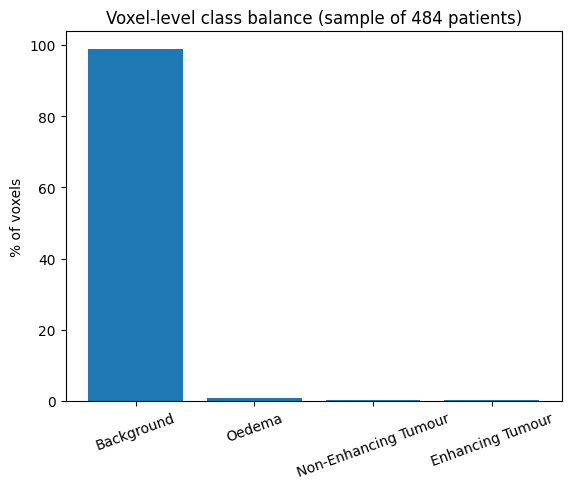

In [ ]:
"""
Voxel-level class balance for the entire dataset based on patient_ids
"""

#0=background, 1=edema, 2=non-enhancing tumor, 3=enhancing tumour.
class_names = ["Background", "Oedema", "Non-Enhancing Tumour", "Enhancing Tumour"]
voxel_counts = np.zeros(4, dtype=np.int64)

sample_size = len(patient_ids)
sample_ids = patient_ids[:sample_size]
for pid in sample_ids:
    label = nib.load(label_files[pid]).get_fdata()
    values, counts = np.unique(label, return_counts=True)
    for v, c in zip(values, counts):
        voxel_counts[int(v)] += c

total_voxels = voxel_counts.sum()
percentages = 100 * voxel_counts / total_voxels

for name, count, pct in zip(class_names, voxel_counts, percentages):
    print(f"{name:30s} {count:>15,d} voxels  ({pct:6.3f}%)")

plt.bar(class_names, percentages)
plt.ylabel("% of voxels")
plt.title(f"Voxel-level class balance (sample of {sample_size} patients)")
plt.xticks(rotation=20)
plt.show()


### Train/val/test split

In [ ]:
from sklearn.model_selection import train_test_split

"""
Two-stage split at patient-level, so no patient's
scans ever appear in more than one of these three sets:
"""

# test set
train_val_ids, test_ids = train_test_split(
    patient_ids, test_size=0.15, random_state=42
)

# train/val set
train_ids, val_ids = train_test_split(
    train_val_ids, test_size=0.15/0.85, random_state=42
)

### Preprocessing Pipeline

FLAIR before -> mean:   516.27 std:   211.65   |   after -> mean:  0.000 std:  1.000
T1    before -> mean:   780.63 std:   206.55   |   after -> mean: -0.000 std:  1.000
T1ce  before -> mean:   728.44 std:   239.42   |   after -> mean: -0.000 std:  1.000
T2    before -> mean:   471.84 std:   211.00   |   after -> mean: -0.000 std:  1.000


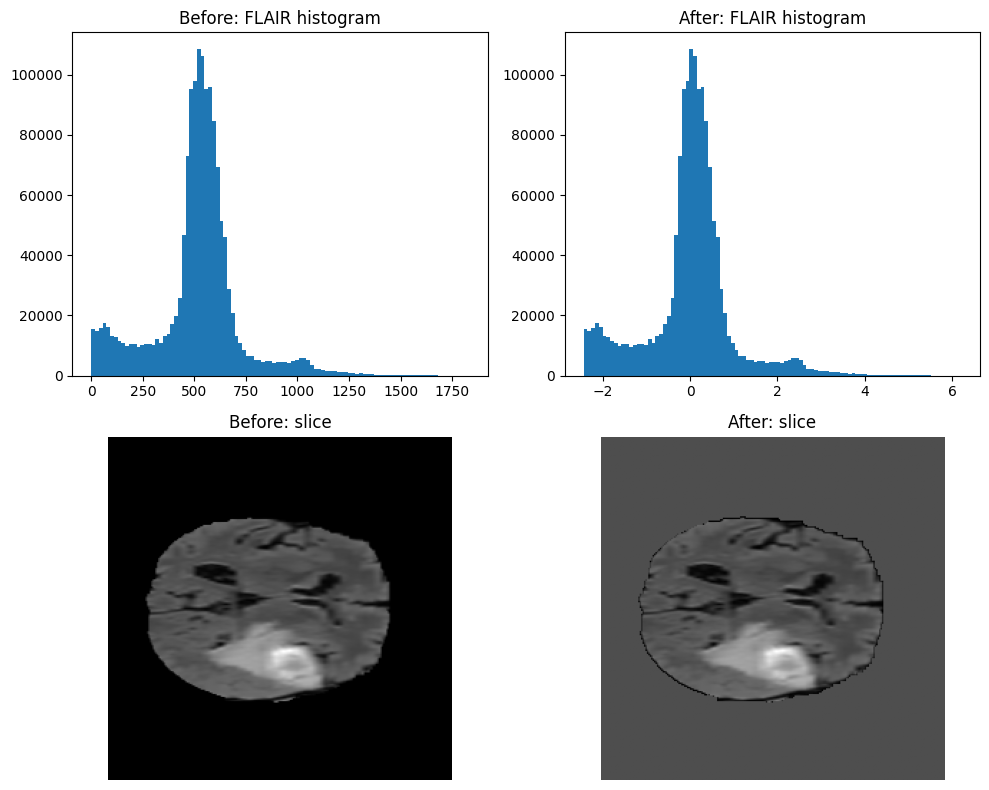

In [ ]:
# Normalization
from monai.transforms import NormalizeIntensity
import numpy as np
import matplotlib.pyplot as plt

# channel_wise: separate mean/std per modality
normalise = NormalizeIntensity(nonzero=True, channel_wise=True)

raw_volume = nib.load(image_files[patient_ids[0]]).get_fdata()   # (H, W, D, 4)
volume_channel_first = np.moveaxis(raw_volume, -1, 0)             # (4, H, W, D)

normalised = normalise(volume_channel_first.copy())

# modality: 0=FLAIR, 1=T1w, 2=T1ce (t1gd), 3=T2w
modality_names = ["FLAIR", "T1", "T1ce", "T2"]
for i, name in enumerate(modality_names):
    before = volume_channel_first[i]
    after = normalised[i]
    print(f"{name:5s} before -> mean: {before[before > 0].mean():8.2f} std: {before[before > 0].std():8.2f}"
          f"   |   after -> mean: {after[after != 0].mean():6.3f} std: {after[after != 0].std():6.3f}")

# visualise one modality (FLAIR)
mod_idx = 0
before_mod = volume_channel_first[mod_idx]
after_mod = normalised[mod_idx]
slice_idx = before_mod.shape[-1] // 2

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].hist(before_mod[before_mod > 0].ravel(), bins=100)
axes[0, 0].set_title(f"Before: {modality_names[mod_idx]} histogram")
axes[0, 1].hist(after_mod[after_mod != 0].ravel(), bins=100)
axes[0, 1].set_title(f"After: {modality_names[mod_idx]} histogram")
axes[1, 0].imshow(before_mod[..., slice_idx], cmap="gray")
axes[1, 0].set_title("Before: slice"); axes[1, 0].axis("off")
axes[1, 1].imshow(after_mod[..., slice_idx], cmap="gray")
axes[1, 1].set_title("After: slice"); axes[1, 1].axis("off")
plt.tight_layout()
plt.show()

### Dataset/Dataloader Design

In [ ]:
def make_data_dicts(ids):
    return [
        {"image": image_files[pid], "label": label_files[pid]}
        for pid in ids
    ]

train_files = make_data_dicts(train_ids)
val_files   = make_data_dicts(val_ids)
test_files  = make_data_dicts(test_ids)

# training: random patch crop + light augmentation
train_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image"], channel_dim=-1),
    EnsureChannelFirstd(keys=["label"], channel_dim="no_channel"),
    NormalizeIntensityd(keys=["image"], channel_wise=True, nonzero=True),
    RandCropByPosNegLabeld(
        keys=["image", "label"],
        label_key="label",
        spatial_size=(96, 96, 96),
        pos=1, neg=1,
        num_samples=2,
    ),
    RandFlipd(keys=["image", "label"], spatial_axis=[0], prob=0.5),
    EnsureTyped(keys=["image", "label"]),
])

# val/test: no cropping or augmentation, deterministic
eval_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image"], channel_dim=-1),
    EnsureChannelFirstd(keys=["label"], channel_dim="no_channel"),
    NormalizeIntensityd(keys=["image"], channel_wise=True, nonzero=True),
    EnsureTyped(keys=["image", "label"]),
])

train_ds = Dataset(data=train_files, transform=train_transforms)
val_ds   = Dataset(data=val_files,   transform=eval_transforms)
test_ds  = Dataset(data=test_files,  transform=eval_transforms)

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True,  num_workers=8)

# batch_size=1: full-size volumes, one at a time via sliding-window inference
val_loader  = DataLoader(val_ds,  batch_size=1, shuffle=False, num_workers=8)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=8)

In [ ]:
print(type(train_loader), type(val_loader), type(test_loader))
batch = next(iter(train_loader))
print(batch["image"].shape, batch["label"].shape)

<class 'monai.data.dataloader.DataLoader'> <class 'monai.data.dataloader.DataLoader'> <class 'monai.data.dataloader.DataLoader'>
torch.Size([4, 4, 96, 96, 96]) torch.Size([4, 1, 96, 96, 96])


### CNN/Segmentation Model Implementation

#### Code: baseline 3D U-Net

In [ ]:
def build_unet():
    return UNet(
        spatial_dims=3,
        in_channels=4,  # modalities (FLAIR, T1, T1ce, T2)
        out_channels=4, # 4 classes coming out per voxel (background, oedema, non-enhancing tumour, enhancing tumour)
        channels=(16, 32, 64, 128, 256),
        strides=(2, 2, 2, 2),
        num_res_units=2,
    ).to(device)

baseline_model = build_unet()

# sanity check: one dummy batch through the model
with torch.no_grad():
    dummy_input = torch.zeros(1, 4, 96, 96, 96).to(device)
    dummy_output = baseline_model(dummy_input)
    print("Output shape:", dummy_output.shape)

Output shape: torch.Size([1, 4, 96, 96, 96])


#### Training loop

In [ ]:
def save_checkpoint(path, model, optimizer, scheduler, epoch, history, run_name):
    # checkpoint
    tmp = path + ".tmp"
    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch,
        "history": history,
        "run_name": run_name,
    }, tmp)
    os.replace(tmp, path)

def train_model(model, train_loader, val_loader, num_epochs, run_name,
                lr=1e-4, weight_decay=1e-5, lambda_ce=1.0, save_path=None):
    loss_function = DiceCELoss(to_onehot_y=True, softmax=True, lambda_ce=lambda_ce)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    history = {"train_loss": [], "val_loss": []}
    start_epoch = 0

    # resume if a checkpoint for this run already exists
    if save_path and os.path.exists(save_path):
        ckpt = torch.load(save_path, map_location=device)
        if ckpt["run_name"] != run_name:
            raise ValueError(f"{save_path} belongs to run '{ckpt['run_name']}', not '{run_name}'")
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        history = ckpt["history"]
        start_epoch = ckpt["epoch"]
        print(f"[{run_name}] resuming after epoch {start_epoch}/{num_epochs}")

    for epoch in range(start_epoch, num_epochs):
        model.train()
        epoch_loss = 0
        for batch in train_loader:
            inputs = batch["image"].to(device)
            labels = batch["label"].to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        scheduler.step()
        avg_train_loss = epoch_loss / len(train_loader)
        history["train_loss"].append(avg_train_loss)

        # fast per-epoch check: val loss only
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                inputs = batch["image"].to(device)
                labels = batch["label"].to(device)
                outputs = sliding_window_inference(inputs, (96, 96, 96), 4, model)
                val_loss += loss_function(outputs, labels).item()
        history["val_loss"].append(val_loss / len(val_loader))

        print(f"[{run_name}] epoch {epoch+1}/{num_epochs} "
              f"train_loss={avg_train_loss:.4f} val_loss={history['val_loss'][-1]:.4f}")

        # full checkpoint after every finished epoch
        if save_path:
            save_checkpoint(save_path, model, optimizer, scheduler, epoch + 1, history, run_name)

    return history


baseline_default_history = train_model(
    baseline_model, train_loader, val_loader,
    num_epochs=50, run_name="baseline_default", lr=1e-4,
)

[baseline_default] epoch 1/50 train_loss=2.0160 val_loss=1.6673
[baseline_default] epoch 2/50 train_loss=1.3934 val_loss=1.1690
[baseline_default] epoch 3/50 train_loss=0.9992 val_loss=0.9047
[baseline_default] epoch 4/50 train_loss=0.8213 val_loss=0.7926
[baseline_default] epoch 5/50 train_loss=0.7407 val_loss=0.7286
[baseline_default] epoch 6/50 train_loss=0.6781 val_loss=0.6742
[baseline_default] epoch 7/50 train_loss=0.6490 val_loss=0.6445
[baseline_default] epoch 8/50 train_loss=0.6252 val_loss=0.5938
[baseline_default] epoch 9/50 train_loss=0.5914 val_loss=0.5633
[baseline_default] epoch 10/50 train_loss=0.5740 val_loss=0.5300
[baseline_default] epoch 11/50 train_loss=0.5545 val_loss=0.5038
[baseline_default] epoch 12/50 train_loss=0.5426 val_loss=0.4744
[baseline_default] epoch 13/50 train_loss=0.5314 val_loss=0.4653
[baseline_default] epoch 14/50 train_loss=0.5197 val_loss=0.4450
[baseline_default] epoch 15/50 train_loss=0.5155 val_loss=0.4296
[baseline_default] epoch 16/50 tra

####  Evaluation by region and by class

In [ ]:
def to_regions(seg):
    # class ids 0-3 (dataset.json: 1 edema, 2 non-enhancing, 3 enhancing)
    # channels: WT = classes 1+2+3, TC = classes 2+3, ET = class 3
    return torch.cat([seg > 0, seg >= 2, seg == 3], dim=1).float()

def to_classes(seg):
    # channels: edema (1), non-enhancing (2), enhancing (3); background left out
    return torch.cat([seg == 1, seg == 2, seg == 3], dim=1).float()

def evaluate_model(model, loader):
    # include_background=True because these 3-channel masks have no background channel to skip
    region_dice = DiceMetric(include_background=True, reduction="mean_batch")
    class_dice = DiceMetric(include_background=True, reduction="mean_batch")

    model.eval()
    with torch.no_grad():
        for batch in loader:
            inputs = batch["image"].to(device)
            labels = batch["label"].to(device)
            outputs = sliding_window_inference(inputs, (96, 96, 96), 4, model)
            pred = torch.argmax(outputs, dim=1, keepdim=True)
            region_dice(y_pred=to_regions(pred), y=to_regions(labels))
            class_dice(y_pred=to_classes(pred), y=to_classes(labels))

    per_region = region_dice.aggregate()
    per_class = class_dice.aggregate()
    region_dice.reset()
    class_dice.reset()
    # per_region channels: 0=Whole Tumour (WT), 1=Tumour Core (TC), 2=Enhancing Tumour (ET)
    # per_class channels: 0=edema, 1=non-enhancing, 2=enhancing
    return {
        "mean_dice": per_region.mean().item(),   # drives tuning and model selection
        "per_region_dice": per_region.tolist(),
        "per_class_dice": per_class.tolist(),
    }

#### Hyperparameter tuning using RandomSearch

In [ ]:
TRIAL_EPOCHS = 5
TUNE_VAL_PATIENTS = 20
N_TRIALS = 20
SEARCH_SEED = 42
MAX_SEARCH_SECONDS = 9 * 3600
TRIALS_FILE = "trials.jsonl"

# fixed validation subset, so every trial is scored on the same patients
tune_val_loader = DataLoader(
    Dataset(data=val_files[:TUNE_VAL_PATIENTS], transform=eval_transforms),
    batch_size=1, shuffle=False, num_workers=8,
)

def log_uniform(rng, low, high):
    # equal chance for each factor-of-ten band between low and high
    return float(np.exp(rng.uniform(np.log(low), np.log(high))))

def sample_params(rng):
    return {
        "lr": log_uniform(rng, 1e-5, 1e-3),
        "weight_decay": log_uniform(rng, 1e-6, 1e-3),
        "lambda_ce": log_uniform(rng, 0.25, 2.0),
    }

# draw every trial's settings up front, so trial i has the same settings in every session
rng = np.random.default_rng(SEARCH_SEED)
all_params = [sample_params(rng) for _ in range(N_TRIALS)]

# anything that changes what a score means goes here; a mismatch stops the notebook
config = {"trial_epochs": TRIAL_EPOCHS, "tune_val_patients": TUNE_VAL_PATIENTS,
          "seed": SEARCH_SEED, "score": "mean Dice of WT/TC/ET"}

# load trials finished in an earlier session
trials = []
if os.path.exists(TRIALS_FILE):
    with open(TRIALS_FILE) as f:
        trials = [json.loads(line) for line in f if line.strip()]
    if any(t["config"] != config for t in trials):
        raise ValueError(f"{TRIALS_FILE} was made with different settings; delete it to start over")
done = {t["trial"] for t in trials}
print("trials already finished:", sorted(done))

def run_trial(i):
    params = all_params[i]
    start = time.time()
    trial_model = build_unet()
    train_model(
        trial_model, train_loader, tune_val_loader,
        num_epochs=TRIAL_EPOCHS, run_name=f"trial{i}", **params,
    )
    score = evaluate_model(trial_model, tune_val_loader)["mean_dice"]
    record = {"trial": i, "mean_dice": score, "params": params, "config": config}
    trials.append(record)
    with open(TRIALS_FILE, "a") as f:
        f.write(json.dumps(record) + "\n")
    print(f"trial {i} finished: mean_dice={score:.4f} in {time.time() - start:.0f} s, params={params}")

trials already finished: []


In [ ]:
# Run the search and save the best settings
search_start = time.time()
for i in range(N_TRIALS):
    if i in done:
        continue
    if time.time() - search_start > MAX_SEARCH_SECONDS:
        print(f"time budget reached, stopping with {len(trials)} of {N_TRIALS} trials finished")
        break
    run_trial(i)

best = max(trials, key=lambda t: t["mean_dice"])
best_params = best["params"]
print("best validation mean Dice:", round(best["mean_dice"], 4), "from", len(trials), "trials")
print("best settings:", best_params)

# top 5 trials
for t in sorted(trials, key=lambda t: t["mean_dice"], reverse=True)[:5]:
    print(t["trial"], round(t["mean_dice"], 4), t["params"])

# save the result so a notebook restart does not lose it
with open("best_params.json", "w") as f:
    json.dump(
        {"best_params": best_params, "best_mean_dice": best["mean_dice"],
         "n_trials_finished": len(trials), "n_trials_planned": N_TRIALS,
         "trial_epochs": TRIAL_EPOCHS, "tune_val_patients": TUNE_VAL_PATIENTS,
         "seed": SEARCH_SEED},
        f, indent=2,
    )

[trial0] epoch 1/5 train_loss=1.7116 val_loss=0.8811
[trial0] epoch 2/5 train_loss=0.8049 val_loss=0.7053
[trial0] epoch 3/5 train_loss=0.7013 val_loss=0.6401
[trial0] epoch 4/5 train_loss=0.6501 val_loss=0.5813
[trial0] epoch 5/5 train_loss=0.6246 val_loss=0.5683
trial 0 finished: mean_dice=0.7250 in 515 s, params={'lr': 0.0003531116913821411, 'weight_decay': 2.0731719263694552e-05, 'lambda_ce': 1.4904972977374944}
[trial1] epoch 1/5 train_loss=2.4726 val_loss=1.4787
[trial1] epoch 2/5 train_loss=1.1540 val_loss=0.8922
[trial1] epoch 3/5 train_loss=0.8517 val_loss=0.7609
[trial1] epoch 4/5 train_loss=0.7680 val_loss=0.7150
[trial1] epoch 5/5 train_loss=0.7390 val_loss=0.7019
trial 1 finished: mean_dice=0.7006 in 502 s, params={'lr': 0.00024816244430149855, 'weight_decay': 1.9166024706981744e-06, 'lambda_ce': 1.9011430030822594}
[trial2] epoch 1/5 train_loss=0.9313 val_loss=0.7444
[trial2] epoch 2/5 train_loss=0.6322 val_loss=0.6145
[trial2] epoch 3/5 train_loss=0.5559 val_loss=0.5591


In [ ]:
# after a notebook restart: reload the saved result instead of re-running the search
with open("best_params.json") as f:
    best_params = json.load(f)["best_params"]
print("loaded best settings:", best_params)

loaded best settings: {'lr': 0.00045212897915896766, 'weight_decay': 7.85223335055597e-05, 'lambda_ce': 1.2093763068704542}


In [28]:
# fresh baseline trained once with the tuned settings
baseline_model = build_unet()
baseline_history = train_model(
    baseline_model, train_loader, val_loader,
    num_epochs=50, run_name="baseline", save_path="baseline_last.pt", **best_params
)

[baseline] epoch 1/50 train_loss=1.1756 val_loss=0.7635
[baseline] epoch 2/50 train_loss=0.7233 val_loss=0.6267
[baseline] epoch 3/50 train_loss=0.6521 val_loss=0.5272
[baseline] epoch 4/50 train_loss=0.5851 val_loss=0.4689
[baseline] epoch 5/50 train_loss=0.5659 val_loss=0.4281
[baseline] epoch 6/50 train_loss=0.5337 val_loss=0.3940
[baseline] epoch 7/50 train_loss=0.5257 val_loss=0.4255
[baseline] epoch 8/50 train_loss=0.5261 val_loss=0.3637
[baseline] epoch 9/50 train_loss=0.5063 val_loss=0.3455
[baseline] epoch 10/50 train_loss=0.5007 val_loss=0.3375
[baseline] epoch 11/50 train_loss=0.5140 val_loss=0.3391
[baseline] epoch 12/50 train_loss=0.4905 val_loss=0.3223
[baseline] epoch 13/50 train_loss=0.5003 val_loss=0.3382
[baseline] epoch 14/50 train_loss=0.4868 val_loss=0.3345
[baseline] epoch 15/50 train_loss=0.4832 val_loss=0.3070
[baseline] epoch 16/50 train_loss=0.4890 val_loss=0.3131
[baseline] epoch 17/50 train_loss=0.4860 val_loss=0.3040
[baseline] epoch 18/50 train_loss=0.4841

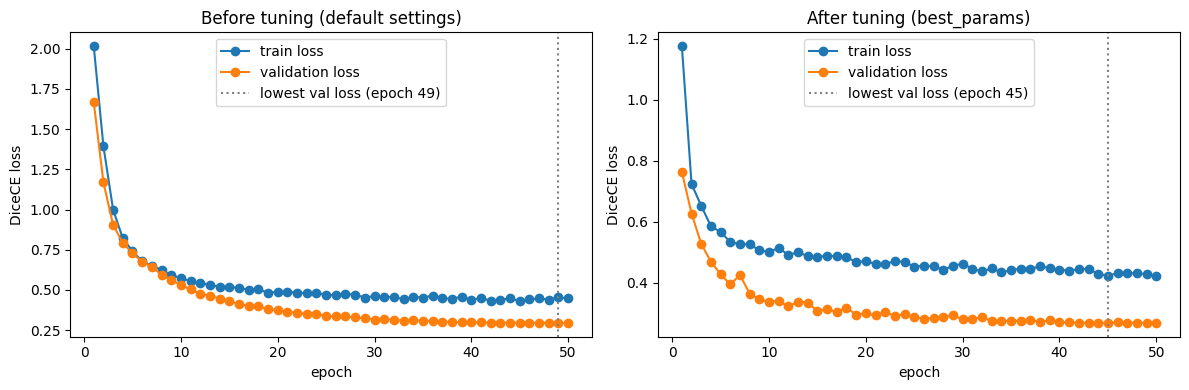

In [29]:
def plot_history(ax, history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    ax.plot(epochs, history["train_loss"], marker="o", label="train loss")
    ax.plot(epochs, history["val_loss"], marker="o", label="validation loss")
    best = int(np.argmin(history["val_loss"]))
    ax.axvline(best + 1, linestyle=":", color="gray", label=f"lowest val loss (epoch {best + 1})")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel("DiceCE loss"); ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_history(axes[0], baseline_default_history, "Before tuning (default settings)")
plot_history(axes[1], baseline_history, "After tuning (best_params)")
plt.tight_layout()
plt.show()